In [1]:
from pathlib import Path

DATA_PATH = Path("mess_mood_meter_one_week_menu_reviews.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Put the CSV beside this notebook "
        "or update DATA_PATH with the correct file path."
    )

print("Dataset found:", DATA_PATH.resolve())

Dataset found: C:\Users\rahul\OneDrive\Desktop\mess_mood_meter\mess_mood_meter_one_week_menu_reviews.csv


In [2]:
# Run only if needed:
# %pip install pandas numpy matplotlib seaborn scikit-learn joblib

import re
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
from sklearn.dummy import DummyClassifier
import joblib

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (560, 9)


,review_id,date,day,meal_slot,menu_item,rating_out_of_5,review_text,sentiment_label_demo,data_type
0,MM00001,2026-11-16,Monday,Breakfast,"Poha with Chutney, sev, onion, lemon",3,"The Poha with Chutney, sev, onion, lemon was neither very good nor very bad today.",Neutral,Synthetic demo review
1,MM00002,2026-11-16,Monday,Breakfast,Milk/Tea/Cofee,4,The Milk/Tea/Cofee was tasty and the overall meal was satisfying.,Positive,Synthetic demo review
2,MM00003,2026-11-16,Monday,Breakfast,Bread-Jam,2,The Bread-Jam was not served warm and the taste could be better.,Negative,Synthetic demo review
3,MM00004,2026-11-16,Monday,Breakfast,Butter,4,Good quality today. The Butter was enjoyable and well seasoned.,Positive,Synthetic demo review
4,MM00005,2026-11-16,Monday,Breakfast,Corn flakes/oats,4,The Corn flakes/oats tasted fresh and was well prepared. I enjoyed this meal.,Positive,Synthetic demo review


In [4]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("data_type"))

print("\nMissing values:")
display(df.isna().sum().to_frame("missing_count"))

print("\nDuplicate complete rows:", df.duplicated().sum())
print("Duplicate review texts:", df["review_text"].duplicated().sum())

Column names:
['review_id', 'date', 'day', 'meal_slot', 'menu_item', 'rating_out_of_5', 'review_text', 'sentiment_label_demo', 'data_type']

Data types:


,data_type
review_id,object
date,object
day,object
meal_slot,object
menu_item,object
rating_out_of_5,int64
review_text,object
sentiment_label_demo,object
data_type,object



Missing values:


,missing_count
review_id,0
date,0
day,0
meal_slot,0
menu_item,0
rating_out_of_5,0
review_text,0
sentiment_label_demo,0
data_type,0



Duplicate complete rows: 0
Duplicate review texts: 261


In [5]:
required_columns = [
    "review_id", "date", "day", "meal_slot", "menu_item",
    "rating_out_of_5", "review_text", "sentiment_label_demo", "data_type"
]

missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["rating_out_of_5"] = pd.to_numeric(df["rating_out_of_5"], errors="coerce")

df["review_text"] = df["review_text"].fillna("").astype(str).str.strip()
df["menu_item"] = df["menu_item"].fillna("Unknown").astype(str).str.strip()
df["sentiment_label_demo"] = df["sentiment_label_demo"].fillna("").astype(str).str.strip().str.title()

valid_labels = ["Negative", "Neutral", "Positive"]
df = df[
    df["review_text"].ne("")
    & df["rating_out_of_5"].between(1, 5)
    & df["sentiment_label_demo"].isin(valid_labels)
].copy()

print("Rows after basic validation:", len(df))
print("\nData type values:")
display(df["data_type"].value_counts().to_frame("rows"))

print("\nSentiment labels:")
display(df["sentiment_label_demo"].value_counts().to_frame("reviews"))

Rows after basic validation: 560

Data type values:


,rows
data_type,
Synthetic demo review,560



Sentiment labels:


,reviews
sentiment_label_demo,
Positive,283
Negative,145
Neutral,132


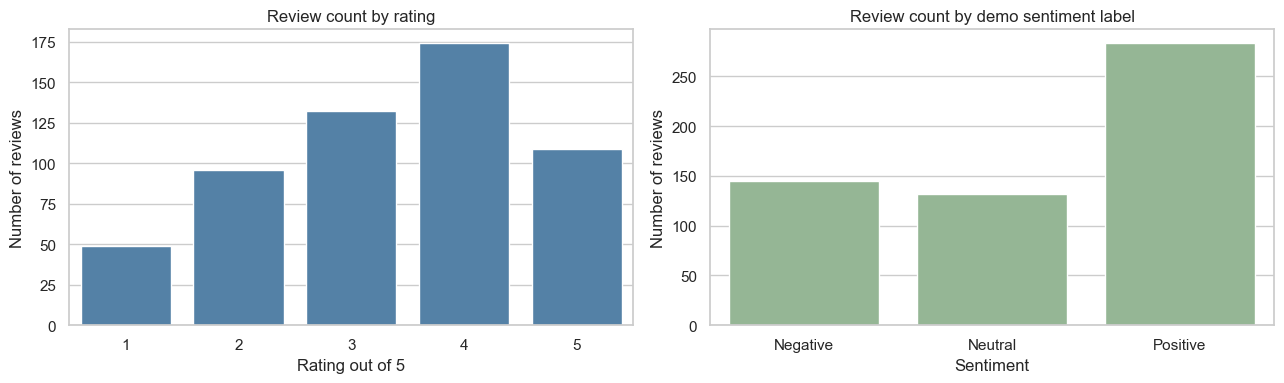

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.countplot(
    data=df, x="rating_out_of_5",
    order=[1, 2, 3, 4, 5], ax=axes[0], color="steelblue"
)
axes[0].set_title("Review count by rating")
axes[0].set_xlabel("Rating out of 5")
axes[0].set_ylabel("Number of reviews")

sentiment_order = ["Negative", "Neutral", "Positive"]
sns.countplot(
    data=df, x="sentiment_label_demo",
    order=sentiment_order, ax=axes[1], color="darkseagreen"
)
axes[1].set_title("Review count by demo sentiment label")
axes[1].set_xlabel("Sentiment")
axes[1].set_ylabel("Number of reviews")

plt.tight_layout()
plt.show()

In [7]:
model_data = df[["review_text", "sentiment_label_demo"]].copy()
model_data["review_text"] = model_data["review_text"].str.lower().str.strip()
model_data = model_data.drop_duplicates(subset="review_text").reset_index(drop=True)

X = model_data["review_text"]
y = model_data["sentiment_label_demo"]

print("Unique review texts used:", len(model_data))
print("\nClass distribution:")
display(y.value_counts().to_frame("count"))

if y.nunique() < 2:
    raise ValueError("At least two sentiment classes are needed to train a classifier.")

Unique review texts used: 299

Class distribution:


,count
sentiment_label_demo,
Positive,127
Neutral,86
Negative,86


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

Training reviews: 224
Testing reviews: 75


In [9]:
sentiment_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        ngram_range=(1, 2),
        min_df=1,
        max_features=5000
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

sentiment_model.fit(X_train, y_train)
print("Model training completed.")

Model training completed.


Accuracy: 1.0

Classification report:
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00        22
     Neutral       1.00      1.00      1.00        21
    Positive       1.00      1.00      1.00        32

    accuracy                           1.00        75
   macro avg       1.00      1.00      1.00        75
weighted avg       1.00      1.00      1.00        75



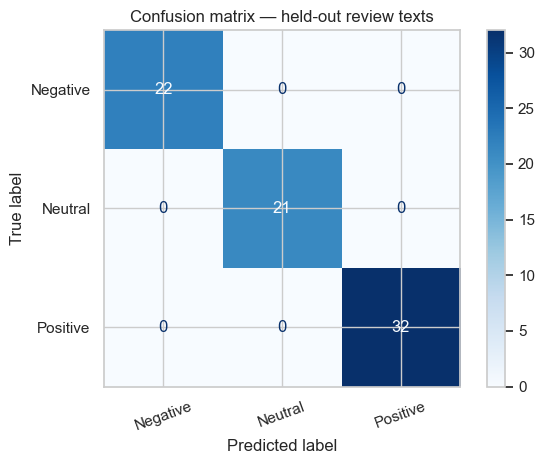

In [10]:
y_pred = sentiment_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification report:")
print(classification_report(y_test, y_pred, labels=sentiment_order, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=sentiment_order,
    display_labels=sentiment_order,
    cmap="Blues",
    xticks_rotation=20
)
plt.title("Confusion matrix — held-out review texts")
plt.tight_layout()
plt.show()

In [11]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train.to_frame(), y_train)
baseline_pred = baseline.predict(X_test.to_frame())

print("Majority baseline accuracy:", round(accuracy_score(y_test, baseline_pred), 4))
print("TF-IDF + Logistic Regression accuracy:", round(accuracy_score(y_test, y_pred), 4))

Majority baseline accuracy: 0.4267
TF-IDF + Logistic Regression accuracy: 1.0


In [12]:
new_review = "The rice was cold and the curry tasted bad."

predicted_sentiment = sentiment_model.predict([new_review])[0]
probabilities = sentiment_model.predict_proba([new_review])[0]
classes = sentiment_model.named_steps["classifier"].classes_

print("Review:", new_review)
print("Predicted sentiment:", predicted_sentiment)
print("Model class probabilities:")
display(
    pd.DataFrame({
        "sentiment": classes,
        "probability": probabilities
    }).sort_values("probability", ascending=False).reset_index(drop=True)
)

Review: The rice was cold and the curry tasted bad.
Predicted sentiment: Neutral
Model class probabilities:


,sentiment,probability
0,Neutral,0.439349
1,Positive,0.319730
2,Negative,0.240922


In [13]:
sentiment_counts = (
    df["sentiment_label_demo"]
    .value_counts()
    .reindex(sentiment_order, fill_value=0)
)

total_reviews = len(df)
positive_pct = 100 * sentiment_counts["Positive"] / total_reviews
neutral_pct = 100 * sentiment_counts["Neutral"] / total_reviews
negative_pct = 100 * sentiment_counts["Negative"] / total_reviews
average_rating = df["rating_out_of_5"].mean()

print(f"Total reviews: {total_reviews}")
print(f"Average rating: {average_rating:.2f}/5")
print(f"Positive: {positive_pct:.1f}%")
print(f"Neutral: {neutral_pct:.1f}%")
print(f"Negative: {negative_pct:.1f}%")

Total reviews: 560
Average rating: 3.35/5
Positive: 50.5%
Neutral: 23.6%
Negative: 25.9%


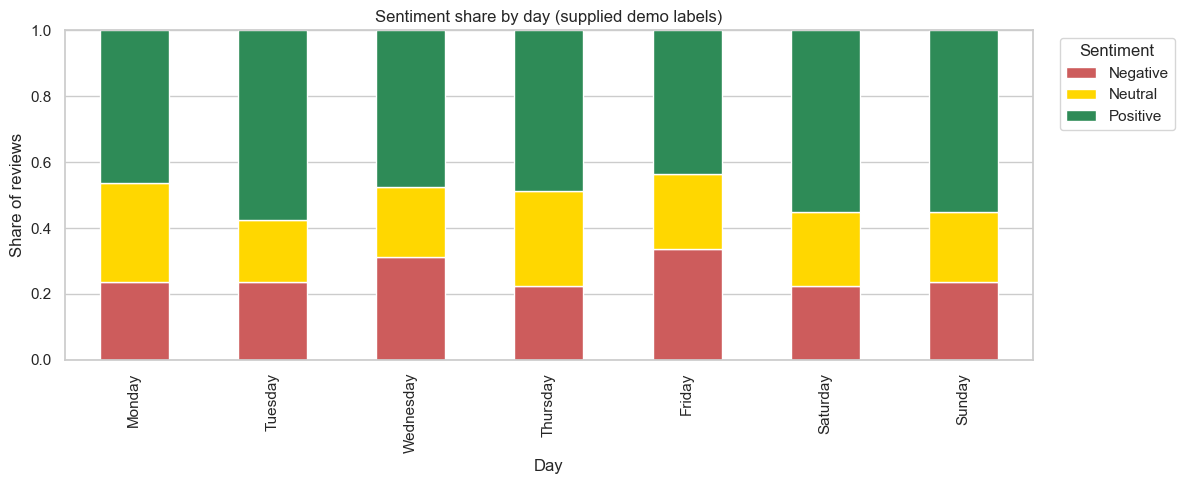

In [14]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

day_sentiment = pd.crosstab(
    df["day"], df["sentiment_label_demo"], normalize="index"
).reindex(day_order).fillna(0)

day_sentiment.plot(
    kind="bar", stacked=True, figsize=(12, 5),
    color=["indianred", "gold", "seagreen"]
)
plt.title("Sentiment share by day (supplied demo labels)")
plt.xlabel("Day")
plt.ylabel("Share of reviews")
plt.ylim(0, 1)
plt.legend(title="Sentiment", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

,reviews,average_rating,positive_reviews,negative_reviews
meal_slot,,,,
Breakfast,140,3.36,70,34
Lunch,140,3.25,61,38
Snacks,140,3.27,68,42
Dinner,140,3.53,84,31


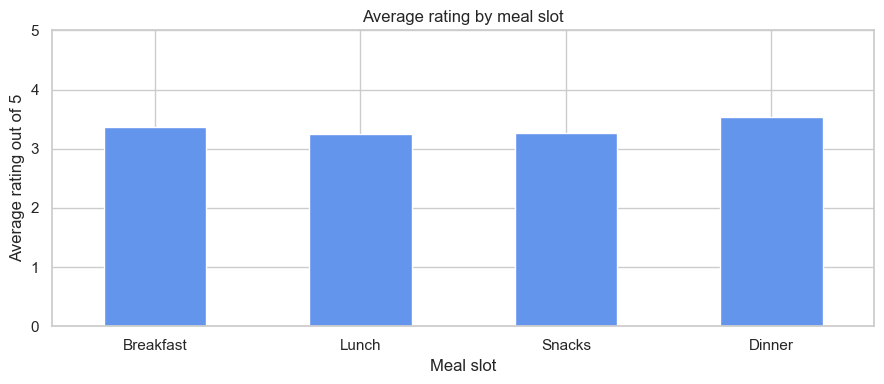

In [15]:
meal_order = ["Breakfast", "Lunch", "Snacks", "Dinner"]

meal_summary = (
    df.groupby("meal_slot")
      .agg(
          reviews=("review_id", "count"),
          average_rating=("rating_out_of_5", "mean"),
          positive_reviews=("sentiment_label_demo", lambda s: (s == "Positive").sum()),
          negative_reviews=("sentiment_label_demo", lambda s: (s == "Negative").sum())
      )
      .reindex(meal_order)
)

display(meal_summary.round(2))

meal_summary["average_rating"].plot(kind="bar", figsize=(9, 4), color="cornflowerblue")
plt.title("Average rating by meal slot")
plt.xlabel("Meal slot")
plt.ylabel("Average rating out of 5")
plt.ylim(0, 5)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [16]:
MIN_REVIEWS_PER_DISH = 3

dish_summary = (
    df.groupby("menu_item")
      .agg(
          review_count=("review_id", "count"),
          average_rating=("rating_out_of_5", "mean"),
          positive_reviews=("sentiment_label_demo", lambda s: (s == "Positive").sum()),
          neutral_reviews=("sentiment_label_demo", lambda s: (s == "Neutral").sum()),
          negative_reviews=("sentiment_label_demo", lambda s: (s == "Negative").sum())
      )
)

dish_summary["positive_pct"] = 100 * dish_summary["positive_reviews"] / dish_summary["review_count"]
dish_summary["negative_pct"] = 100 * dish_summary["negative_reviews"] / dish_summary["review_count"]

eligible_dishes = dish_summary[dish_summary["review_count"] >= MIN_REVIEWS_PER_DISH]

print("Top-rated dishes (minimum review threshold applied):")
display(eligible_dishes.sort_values(
    ["average_rating", "review_count"], ascending=[False, False]
).head(10).round(2))

print("Lowest-rated dishes (minimum review threshold applied):")
display(eligible_dishes.sort_values(
    ["average_rating", "review_count"], ascending=[True, False]
).head(10).round(2))

Top-rated dishes (minimum review threshold applied):


,review_count,average_rating,positive_reviews,neutral_reviews,negative_reviews,positive_pct,negative_pct
menu_item,,,,,,,
Matar Masala,3,4.33,3,0,0,100.00,0.00
Puri (Alternate Weeks),3,4.33,2,1,0,66.67,0.00
Punugulu,7,4.14,5,1,1,71.43,14.29
Aloo /Batani Pani Puri (*7 Pieces) (Alternate Weeks),10,4.10,8,1,1,80.00,10.00
Onion Palak Pakoda (Alternate Weeks),7,4.00,5,2,0,71.43,0.00
Aloo/Veg Parata,3,4.00,2,1,0,66.67,0.00
Sprouts,14,3.93,10,4,0,71.43,0.00
Dal,24,3.83,17,5,2,70.83,8.33
Curd,27,3.81,20,2,5,74.07,18.52


Lowest-rated dishes (minimum review threshold applied):


,review_count,average_rating,positive_reviews,neutral_reviews,negative_reviews,positive_pct,negative_pct
menu_item,,,,,,,
Masala Sandwich,10,2.20,3,1,6,30.00,60.00
Sweet Corn (Alternate Weeks),7,2.57,2,1,4,28.57,57.14
Besan Chilla,3,2.67,1,1,1,33.33,33.33
"Poha with Chutney, sev, onion, lemon",3,2.67,0,2,1,0.00,33.33
Seasonal Fruit,4,2.75,1,1,2,25.00,50.00
Sambar/Rasam,26,2.77,8,6,12,30.77,46.15
Vegetable Curry,13,2.92,5,3,5,38.46,38.46
Veg puff,7,3.00,2,2,3,28.57,42.86
Masala Dosa with Chutney and Sambar,3,3.00,1,1,1,33.33,33.33


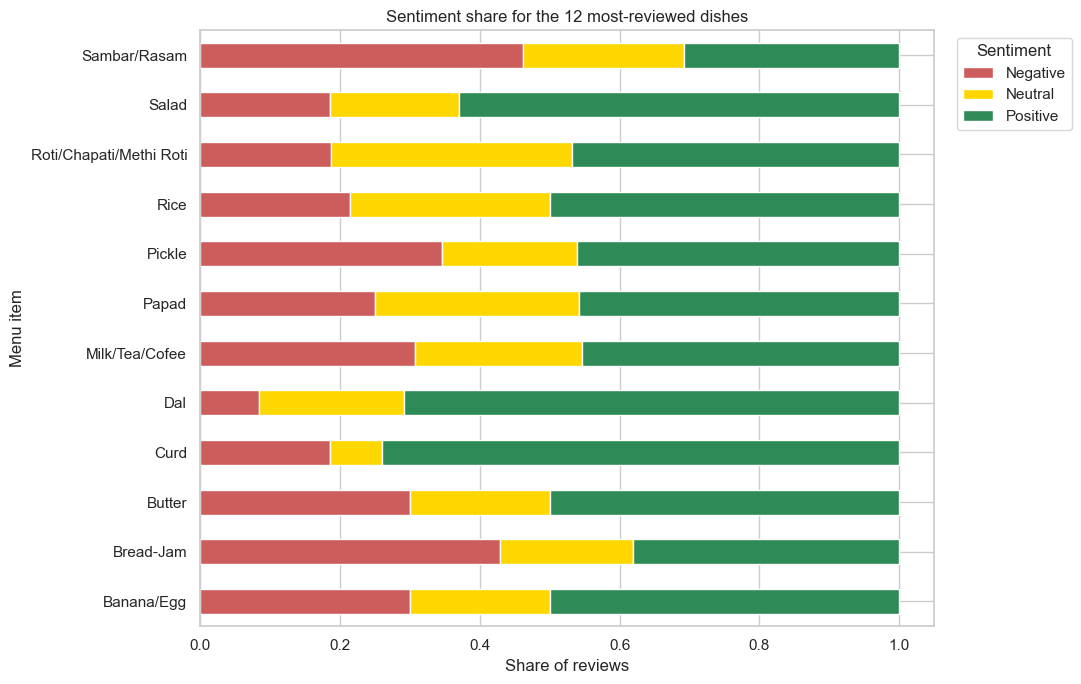

In [17]:
top_dishes = df["menu_item"].value_counts().head(12).index
dish_sentiment = pd.crosstab(
    df[df["menu_item"].isin(top_dishes)]["menu_item"],
    df[df["menu_item"].isin(top_dishes)]["sentiment_label_demo"],
    normalize="index"
).reindex(columns=sentiment_order, fill_value=0)

dish_sentiment.plot(
    kind="barh", stacked=True, figsize=(11, 7),
    color=["indianred", "gold", "seagreen"]
)
plt.title("Sentiment share for the 12 most-reviewed dishes")
plt.xlabel("Share of reviews")
plt.ylabel("Menu item")
plt.legend(title="Sentiment", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

,average_rating,review_count
date,,
2026-11-16,3.32,80
2026-11-17,3.50,80
2026-11-18,3.28,80
2026-11-19,3.34,80
2026-11-20,3.20,80
2026-11-21,3.41,80
2026-11-22,3.42,80


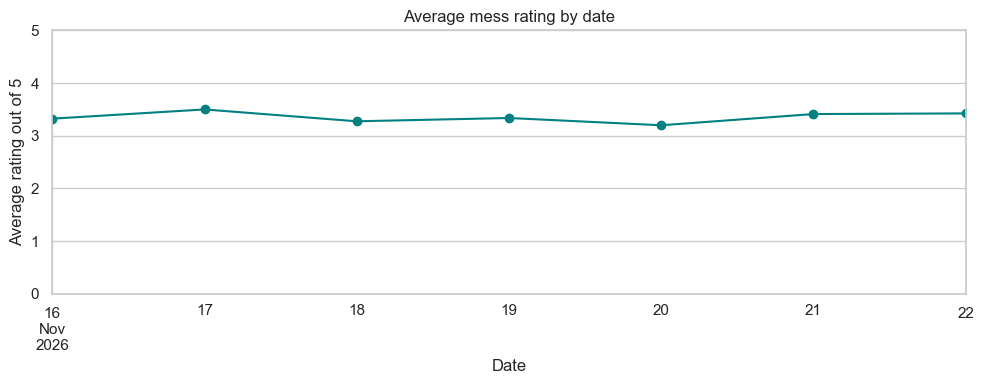

In [18]:
date_summary = (
    df.groupby("date")
      .agg(
          average_rating=("rating_out_of_5", "mean"),
          review_count=("review_id", "count")
      )
      .sort_index()
)

display(date_summary.round(2))

date_summary["average_rating"].plot(marker="o", figsize=(10, 4), color="teal")
plt.title("Average mess rating by date")
plt.xlabel("Date")
plt.ylabel("Average rating out of 5")
plt.ylim(0, 5)
plt.tight_layout()
plt.show()

In [19]:
MODEL_PATH = Path("mess_mood_sentiment_model.joblib")
joblib.dump(sentiment_model, MODEL_PATH)
print("Saved model to:", MODEL_PATH.resolve())

Saved model to: C:\Users\rahul\OneDrive\Desktop\mess_mood_meter\mess_mood_sentiment_model.joblib


In [20]:
dish_summary.reset_index().to_csv("dish_summary.csv", index=False)
meal_summary.reset_index().to_csv("meal_summary.csv", index=False)
day_sentiment.reset_index().to_csv("day_sentiment_summary.csv", index=False)

print("Exported:")
print("- dish_summary.csv")
print("- meal_summary.csv")
print("- day_sentiment_summary.csv")

Exported:
- dish_summary.csv
- meal_summary.csv
- day_sentiment_summary.csv
